# Train — DenseNet-121

Trains and evaluates DenseNet-121 with the tuned hyperparameters in `ARCH_HYPERPARAMS["densenet121"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: off
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["densenet121"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"DenseNet-121: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

DenseNet-121: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 24)
Train: 1348 | Val: 323 | Test: 856


## Model

In [3]:
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
in_f = model.classifier.in_features
model.classifier = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[DenseNet-121] Gradient accumulation: 2 micro-batches per optimizer step.


[DenseNet-121] Epoch   1/100 | LR: 1.38e-04 | train loss 0.7846 acc 0.636 | val loss 0.5879 acc 0.765 *


[DenseNet-121] Epoch   2/100 | LR: 1.38e-04 | train loss 0.4145 acc 0.801 | val loss 0.6585 acc 0.718


[DenseNet-121] Epoch   3/100 | LR: 1.38e-04 | train loss 0.3294 acc 0.862 | val loss 0.4958 acc 0.811 *


[DenseNet-121] Epoch   4/100 | LR: 1.38e-04 | train loss 0.2175 acc 0.902 | val loss 0.6562 acc 0.808


...

[DenseNet-121] Epoch   9/100 | LR: 1.38e-04 | train loss 0.0879 acc 0.967 | val loss 0.5423 acc 0.833


[DenseNet-121] Epoch  10/100 | LR: 1.38e-04 | train loss 0.0552 acc 0.978 | val loss 0.6536 acc 0.808


[DenseNet-121] Epoch  11/100 | LR: 1.38e-04 | train loss 0.0759 acc 0.962 | val loss 0.6565 acc 0.839


[DenseNet-121] Epoch  12/100 | LR: 1.38e-04 | train loss 0.1194 acc 0.961 | val loss 0.6795 acc 0.765


[DenseNet-121] Epoch  13/100 | LR: 1.38e-04 | train loss 0.0723 acc 0.973 | val loss 0.7809 acc 0.830

[DenseNet-121] No val loss improvement for 10 epochs, stopping at epoch 13.

[DenseNet-121] Restored best checkpoint (val loss = 0.4958)


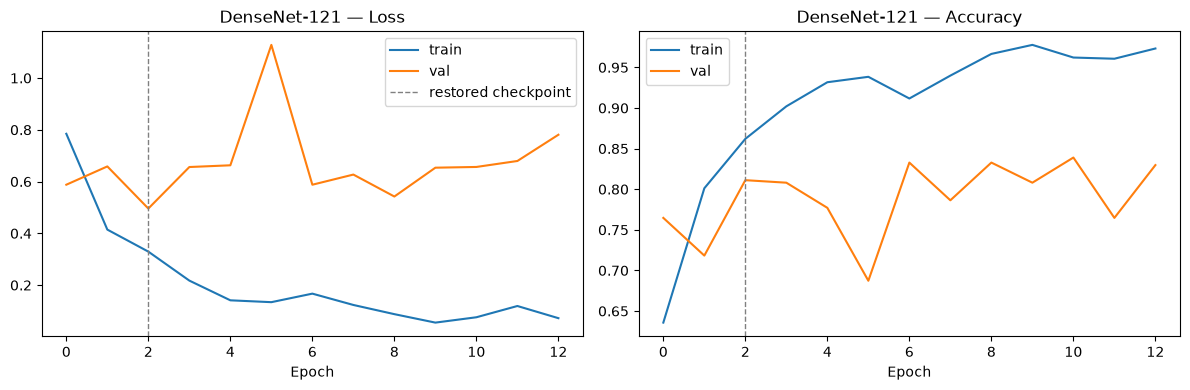

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "DenseNet-121", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "DenseNet-121")

## Evaluate on the test set

[DenseNet-121] Test accuracy: 0.777


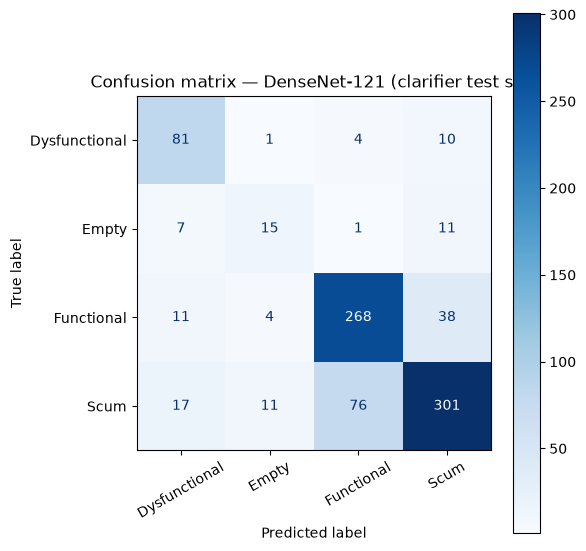

               precision    recall  f1-score   support

Dysfunctional      0.698     0.844     0.764        96
        Empty      0.484     0.441     0.462        34
   Functional      0.768     0.835     0.800       321
         Scum      0.836     0.743     0.787       405

     accuracy                          0.777       856
    macro avg      0.697     0.716     0.703       856
 weighted avg      0.781     0.777     0.776       856



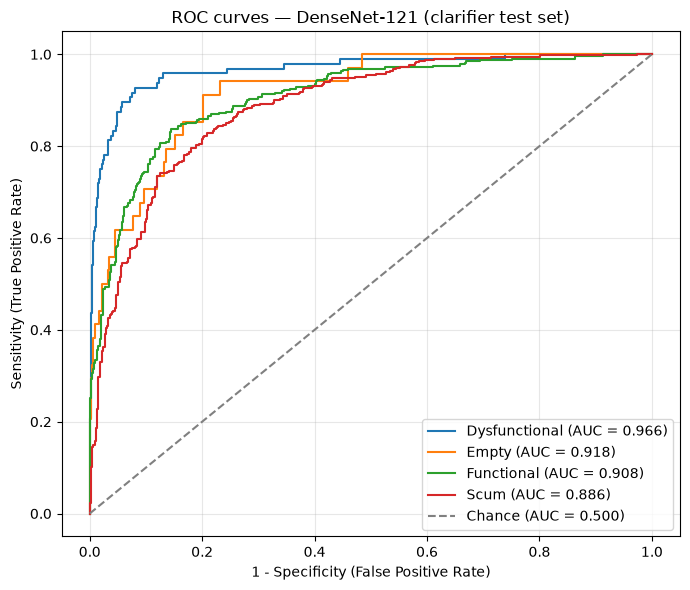

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.966
  Empty          : 0.918
  Functional     : 0.908
  Scum           : 0.886

Mean AUC (over 4/4 classes with test examples): 0.919


(np.float64(0.7768691588785047),
 {'Dysfunctional': 0.9660224780701755,
  'Empty': 0.9177400887362245,
  'Functional': 0.9076658805718113,
  'Scum': 0.8856806547863458})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "DenseNet-121", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("DenseNet-121", "densenet121")

Saved results to ../results/clarifier_noaug/results_clarifier_densenet121_chronological.pkl
Saved model weights to ../models/pad/clarifier_noaug/clarifier_densenet121_chronological.pt
